# Fine-tuning con LoRA: Qwen3-4B

Este notebook realiza el fine-tuning del modelo **Qwen3-4B** mediante **LoRA** (Low-Rank Adaptation) para la tarea de clasificacion ideologica de noticias espanolas en tres clases:
**IZQUIERDA**, **CENTRO** y **DERECHA**.

### Variante: LoRA r=8, lora_alpha=16, target_modules=all-linear

### Justificacion de LoRA
Se usa LoRA en lugar de fine-tuning completo por tres razones:
1. **Pocos datos**: 1,902 ejemplos de entrenamiento son insuficientes para reentrenar 4B parametros sin sobreajuste. LoRA entrena solo ~1% de parametros adicionales (Hu et al., 2021).
2. **VRAM limitada**: Qwen3-4B en full fine-tuning requiere >40 GB de VRAM. Con LoRA mas cuantizacion 4-bit cabe en ~9 GB (T4 de Colab).
3. **Preservar conocimiento**: LoRA congela los pesos del modelo base, preservando su comprension del espanol y adaptando solo las capas de atencion al dominio ideologico.


## 1. Montar Google Drive


In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')

assert os.path.exists('/content/drive/MyDrive'), (
    'Drive no montado correctamente. Vuelve a ejecutar esta celda.'
)
print('Drive montado correctamente')
print('Contenido de MyDrive/TFM (si existe):')
tfm_path = '/content/drive/MyDrive/TFM'
if os.path.exists(tfm_path):
    for item in sorted(os.listdir(tfm_path)):
        print(f'  {item}')
else:
    print('  La carpeta TFM no existe todavia en Drive. Se creara al guardar.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive montado correctamente
Contenido de MyDrive/TFM (si existe):
  comparativa
  qwen3_4b_lora
  qwen3_4b_lora_alllinear_r8
  qwen3_4b_lora_full7_r8
  qwen3_4b_lora_mlp16
  qwen3_4b_lora_mlp32
  qwen3_4b_lora_r8_qkv
  qwen3_4b_lora_regularized
  qwen3_4b_qlora
  splits


## 2. Instalación de dependencias e Imports

Todas las dependencias y todos los imports de Python se recogen en las celdas de esta sección.

In [2]:
# Verificar GPU antes de instalar
!nvidia-smi

!pip install -q --upgrade transformers>=4.51.0 peft>=0.14.0 \
             bitsandbytes accelerate datasets sentencepiece trl
!pip install -q lime
!pip install -q --upgrade torchao

Thu May 21 10:16:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   33C    P0             48W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 3. Imports y configuración global

Todos los imports de Python están en la celda siguiente. A continuación se definen las constantes de configuración.

In [3]:
# (pip install movido a la celda de dependencias al inicio)

In [4]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_recall_fscore_support,
    cohen_kappa_score, confusion_matrix,
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    BitsAndBytesConfig,
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training
from datasets import Dataset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



import shap
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd


import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import log_softmax

from lime.lime_text import LimeTextExplainer
import matplotlib.patches as mpatches
import torch
from sklearn.metrics import f1_score
from IPython.display import display, HTML
import transformers
print(f'transformers version: {transformers.__version__}')

In [5]:
# Semilla global para reproducibilidad (permite comparar notebooks)
SEED = 42
import random, numpy as np, torch
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Codificacion de etiquetas
LABEL2ID = {'IZQUIERDA': 0, 'CENTRO': 1, 'DERECHA': 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
CLASES   = ['IZQUIERDA', 'CENTRO', 'DERECHA']

MODEL_NAME = 'Qwen/Qwen3-4B'
OUTPUT_DIR = '/content/drive/MyDrive/TFM/qwen3_4b_lora_alllinear_r8'

# Copiar datos de Drive a disco local para mayor velocidad
import shutil, os
os.makedirs('/content/splits', exist_ok=True)
shutil.copy('/content/drive/MyDrive/TFM/splits/df_train.parquet', '/content/splits/df_train.parquet')
shutil.copy('/content/drive/MyDrive/TFM/splits/df_val.parquet',   '/content/splits/df_val.parquet')
SPLITS_DIR = '/content/splits/'

# Crear carpeta de output si no existe
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

# Verificar GPU
print(f'GPU disponible : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU            : {torch.cuda.get_device_name(0)}')
    print(f'VRAM total     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print(f'SPLITS_DIR     : {SPLITS_DIR}')
print(f'OUTPUT_DIR     : {OUTPUT_DIR}')


GPU disponible : True
GPU            : NVIDIA RTX PRO 6000 Blackwell Server Edition
VRAM total     : 102.0 GB
SPLITS_DIR     : /content/splits/
OUTPUT_DIR     : /content/drive/MyDrive/TFM/qwen3_4b_lora_alllinear_r8


## 4. Cargar datos de entrenamiento y validacion

Cargamos df_train y df_val desde Drive. La columna `texto` contiene el articulo
completo (titular + abstract + noticia) construido en el notebook de preprocesado.
La columna `final_label` contiene la etiqueta ideologica del ground truth.

df_test NO se carga aqui. Se reserva para la comparativa final de la Seccion 6, ya que si se usara aqui para ajustar hiperparametros dejaria de ser una medida honesta del modelo.

In [6]:
df_train = pd.read_parquet(SPLITS_DIR + 'df_train.parquet')
df_val   = pd.read_parquet(SPLITS_DIR + 'df_val.parquet')

# Verificar columnas
print('Columnas df_train:', df_train.columns.tolist())
assert 'texto' in df_train.columns, 'Columna texto no encontrada en df_train'
assert 'final_label' in df_train.columns, 'Columna final_label no encontrada en df_train'

print(f'\nTrain : {len(df_train):,} articulos')
print(f'Val   : {len(df_val):,} articulos')
print(f'\nDistribucion train:')
print(df_train['final_label'].value_counts().to_string())
print(f'\nDistribucion val:')
print(df_val['final_label'].value_counts().to_string())
print(f'\nLongitud media texto train : {df_train["texto"].str.len().mean():.0f} caracteres')
print(f'Longitud maxima texto train: {df_train["texto"].str.len().max():,} caracteres')


Columnas df_train: ['id', 'texto', 'medio', 'final_label', 'accion']

Train : 1,902 articulos
Val   : 238 articulos

Distribucion train:
final_label
CENTRO       766
IZQUIERDA    672
DERECHA      464

Distribucion val:
final_label
CENTRO       96
IZQUIERDA    84
DERECHA      58

Longitud media texto train : 4521 caracteres
Longitud maxima texto train: 32,165 caracteres


## 5. Cargar el modelo

Se usa AutoModelForSequenceClassification en lugar del modelo generativo porque:
- Añade una cabeza de clasificacion lineal sobre el transformer
- Es mas eficiente para clasificacion que generar texto token a token
- Permite obtener probabilidades directamente via softmax sobre los logits

In [7]:
# Sin cuantizacion — carga estandar bfloat16
print('Cargando tokenizer...')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f'Vocabulario: {tokenizer.vocab_size:,} tokens')

print('\nCargando modelo (1-2 min)...')
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    torch_dtype=torch.bfloat16,
    device_map='auto',
    trust_remote_code=True,
)
model.config.pad_token_id = tokenizer.pad_token_id

vram_used = torch.cuda.memory_allocated() / 1e9
print(f'Modelo cargado VRAM usada: {vram_used:.1f} GB')


Cargando tokenizer...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Vocabulario: 151,643 tokens

Cargando modelo (1-2 min)...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo cargado VRAM usada: 8.0 GB


## 6. Configurar LoRA

**Variante: LoRA All-linear r8**

Se aplica LoRA sobre todas las capas lineales del transformer (atención y MLP), con rango r=8 y lora_alpha=16.

Parámetros clave:
- `r=8`: rango bajo sobre todas las capas lineales — mayor cobertura de capas que QV o QKV, pero con el mismo rango por módulo.
- `lora_alpha=16`: escala de LoRA. Regla habitual: alpha = 2 × r.
- `lora_dropout=0.1`: regularización para limitar la memorización.
- `target_modules=all linear`: se adaptan las proyecciones de atención (Q, K, V, O) y las de las MLP (gate, up, down), cubriendo la mayor superficie de adaptación de toda la batería.

Con esta configuración se entrenan 16,522,752 parámetros (0.4091 % del total). La hipótesis es que adaptar todas las capas permite capturar patrones ideológicos tanto en el mecanismo de atención como en el procesamiento feed-forward.

In [8]:
# (pip install movido a la celda de dependencias al inicio)

In [9]:
# r=8, alpha=16, target_modules='all-linear'
# Logica: all-linear aplica LoRA a TODAS las capas lineales del modelo
# (atencion q/k/v/o, MLP gate/up/down, lm_head, clasificador, embeddings).
# Se baja r a 8 (y alpha a 16) para compensar el aumento masivo de parametros.
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules='all-linear',
    bias='none',
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


trainable params: 16,522,752 || all params: 4,038,998,528 || trainable%: 0.4091


### Parámetros entrenables

Con r=8 sobre todas las capas lineales se entrenan **16,522,752 parámetros** (0.4091 % del total de Qwen3-4B). Esta es la variante que cubre la mayor superficie del modelo, aunque con el mismo rango r=8 por módulo que las variantes de atención.

Con 1,902 ejemplos de entrenamiento y 16.5 M de parámetros ajustables, el riesgo de memorización es considerable. El overfitting más severo de toda la batería (subida de val_loss de 1.038 puntos) confirma que adaptar todas las capas lineales no es la estrategia óptima con este tamaño de dataset.

## 7. Tokenizar los datasets

Convertimos los DataFrames de pandas a formato HuggingFace Dataset.

El tokenizer convierte el texto en secuencias de token IDs que el modelo entiende.
Se aplica truncado a max_length=1024 tokens cuando el articulo es mas largo.
No se trunca el texto manualmente antes: se pasa el campo texto completo
y el tokenizer decide el corte.

Con una longitud media de ~ 4,455 caracteres (~1,100 tokens), max_length=1024 cubre aproximadamente el 70 por ciento de los articulos completos.
La informacion ideologica relevante se concentra en el titular y los primeros parrafos, por lo que el truncado no supone una perdida significativa de senal.

padding=False en el tokenizer y DataCollatorWithPadding en el Trainer hacen padding
dinamico por batch: cada batch se padea solo hasta el ejemplo mas largo de ese batch,
no hasta max_length. Esto ahorra VRAM y acelera el entrenamiento.


In [10]:
MAX_LENGTH = 1024

def tokenize(batch):
    return tokenizer(
        batch['texto'],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )

def make_dataset(df):
    ds = Dataset.from_dict({
        'texto': df['texto'].tolist(),
        'label': df['final_label'].map(LABEL2ID).tolist(),
    })
    return ds.map(tokenize, batched=True, remove_columns=['texto'])

print('Tokenizando datasets...')
ds_train = make_dataset(df_train)
ds_val   = make_dataset(df_val)

print(f'Train: {len(ds_train):,} ejemplos')
print(f'Val  : {len(ds_val):,} ejemplos')
print(f'Columnas: {ds_train.column_names}')


Tokenizando datasets...


Map:   0%|          | 0/1902 [00:00<?, ? examples/s]

Map:   0%|          | 0/238 [00:00<?, ? examples/s]

Train: 1,902 ejemplos
Val  : 238 ejemplos
Columnas: ['label', 'input_ids', 'attention_mask']


## 8. Funcion de metricas

Las metricas que se calculan al final de cada epoca sobre el conjunto de validacion.

La metrica principal es F1-macro porque:
- Trata las tres clases (IZQUIERDA, CENTRO, DERECHA) por igual
- No se ve distorsionada por el desbalanceo de clases (CENTRO=40%, DERECHA=24%)
- Es el estandar en papers de clasificacion ideologica y de texto en general

El checkpoint que se guarda como mejor es el que maximiza F1-macro en validacion,no el del ultimo epoch.


In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc      = accuracy_score(labels, preds)
    f1_macro = f1_score(labels, preds, average='macro',    labels=[0,1,2], zero_division=0)
    f1_w     = f1_score(labels, preds, average='weighted', labels=[0,1,2], zero_division=0)
    kappa    = cohen_kappa_score(labels, preds)

    probs     = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=-1).numpy()
    confianza = probs.max(axis=1).mean()

    prec, rec, f1_per, _ = precision_recall_fscore_support(
        labels, preds, labels=[0,1,2], zero_division=0
    )

    return {
        'accuracy':    round(acc, 4),
        'f1_macro':    round(f1_macro, 4),
        'f1_weighted': round(f1_w, 4),
        'kappa':       round(kappa, 4),
        'confianza':   round(float(confianza), 4),
        'f1_izq':      round(f1_per[0], 4),
        'f1_cen':      round(f1_per[1], 4),
        'f1_der':      round(f1_per[2], 4),
        'prec_izq':    round(prec[0], 4),
        'prec_cen':    round(prec[1], 4),
        'prec_der':    round(prec[2], 4),
        'rec_izq':     round(rec[0], 4),
        'rec_cen':     round(rec[1], 4),
        'rec_der':     round(rec[2], 4),
    }

print('Funcion de metricas definida')


Funcion de metricas definida


## 9. TrainingArguments

Configuracion del entrenamiento.


In [12]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    # Epocas y batch
    num_train_epochs=10,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=8,

    # Optimizacion
    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_ratio=0.1,
    bf16=True,

    # Evaluacion y guardado
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    greater_is_better=True,

    # Logging
    logging_steps=20,
    report_to='none',
    seed=42,
)

batch_efectivo = training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps
pasos_por_epoca = len(ds_train) // batch_efectivo
print(f'Batch efectivo  : {batch_efectivo}')
print(f'Pasos por epoca : {pasos_por_epoca}')
print(f'Total pasos     : {pasos_por_epoca * training_args.num_train_epochs}')


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Batch efectivo  : 32
Pasos por epoca : 59
Total pasos     : 590


## 10. Trainer y entrenamiento

Lanzamos el entrenamiento.

DataCollatorWithPadding realiza padding dinamico: padea cada batch solo hasta
el ejemplo mas largo de ese batch, no hasta max_length=1024. Esto ahorra VRAM
y acelera el entrenamiento cuando los articulos son de longitud variable.


In [13]:
!nvidia-smi

Thu May 21 10:16:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   33C    P0             86W /  600W |    8385MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [14]:
import gc
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
print(f'VRAM libre: {(torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated()) / 1e9:.1f} GB')

VRAM libre: 93.9 GB


In [15]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

# Detectar checkpoint previo para reanudar si la sesion se corto
checkpoints = sorted(Path(OUTPUT_DIR).glob('checkpoint-*'))
last_checkpoint = str(checkpoints[-1]) if checkpoints else None

if last_checkpoint:
    print(f'Checkpoint encontrado: {last_checkpoint}')
    print('Reanudando entrenamiento desde ese punto...')
else:
    print('Iniciando entrenamiento desde cero...')

trainer.train(resume_from_checkpoint=last_checkpoint)

print('Entrenamiento completado')


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Iniciando entrenamiento desde cero...


[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Kappa,Confianza,F1 Izq,F1 Cen,F1 Der,Prec Izq,Prec Cen,Prec Der,Rec Izq,Rec Cen,Rec Der
1,7.596790,0.810023,0.626100,0.504300,0.563000,0.403400,0.727700,0.626700,0.787900,0.098400,0.511300,0.764700,1.000000,0.809500,0.812500,0.051700
2,4.500397,0.560967,0.764700,0.762800,0.765300,0.643400,0.781500,0.766500,0.776000,0.746000,0.771100,0.816100,0.691200,0.761900,0.739600,0.810300
3,2.640894,0.523755,0.798300,0.793100,0.798600,0.691300,0.841700,0.771900,0.842100,0.765200,0.758600,0.851100,0.771900,0.785700,0.833300,0.758600
4,0.811521,0.838593,0.823500,0.817400,0.822600,0.727100,0.951000,0.839500,0.835000,0.777800,0.871800,0.781800,0.840000,0.809500,0.895800,0.724100


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Kappa,Confianza,F1 Izq,F1 Cen,F1 Der,Prec Izq,Prec Cen,Prec Der,Rec Izq,Rec Cen,Rec Der
1,7.596790,0.810023,0.626100,0.504300,0.563000,0.403400,0.727700,0.626700,0.787900,0.098400,0.511300,0.764700,1.000000,0.809500,0.812500,0.051700
2,4.500397,0.560967,0.764700,0.762800,0.765300,0.643400,0.781500,0.766500,0.776000,0.746000,0.771100,0.816100,0.691200,0.761900,0.739600,0.810300
3,2.640894,0.523755,0.798300,0.793100,0.798600,0.691300,0.841700,0.771900,0.842100,0.765200,0.758600,0.851100,0.771900,0.785700,0.833300,0.758600
4,0.811521,0.838593,0.823500,0.817400,0.822600,0.727100,0.951000,0.839500,0.835000,0.777800,0.871800,0.781800,0.840000,0.809500,0.895800,0.724100
5,0.138002,1.557053,0.806700,0.804900,0.808500,0.706100,0.960200,0.782100,0.842700,0.789900,0.736800,0.914600,0.770500,0.833300,0.781200,0.810300
6,0.013273,1.609264,0.802500,0.794900,0.801000,0.694400,0.976900,0.807700,0.824600,0.752300,0.875000,0.756500,0.803900,0.750000,0.906200,0.706900
7,0.000504,1.490798,0.823500,0.821300,0.823200,0.728900,0.970100,0.807200,0.842600,0.814200,0.817100,0.821800,0.836400,0.797600,0.864600,0.793100
8,0.000028,1.590041,0.823500,0.817400,0.822400,0.728000,0.973900,0.817600,0.848800,0.785700,0.866700,0.798200,0.814800,0.773800,0.906200,0.758600
9,0.000018,1.555380,0.819300,0.813800,0.818300,0.721600,0.974300,0.812500,0.843100,0.785700,0.855300,0.796300,0.814800,0.773800,0.895800,0.758600
10,0.000015,1.561560,0.823500,0.818800,0.822600,0.728400,0.973400,0.812500,0.847300,0.796500,0.855300,0.803700,0.818200,0.773800,0.895800,0.775900


Entrenamiento completado


## 11. Métricas finales en validación

Evaluamos el mejor checkpoint sobre los 238 artículos de validación. `load_best_model_at_end=True` garantiza que se carga el checkpoint con mayor F1-macro, no el del último epoch.

In [16]:
print('Evaluando en validacion...')
val_output = trainer.predict(ds_val)

logits = val_output.predictions
labels = val_output.label_ids
probs  = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=-1).numpy()
preds  = np.argmax(probs, axis=-1)

acc      = accuracy_score(labels, preds)
f1_macro = f1_score(labels, preds, average='macro',    labels=[0,1,2], zero_division=0)
f1_w     = f1_score(labels, preds, average='weighted', labels=[0,1,2], zero_division=0)
kappa    = cohen_kappa_score(labels, preds)
conf     = probs.max(axis=1).mean()

prec, rec, f1_per, _ = precision_recall_fscore_support(
    labels, preds, labels=[0,1,2], zero_division=0
)
cm = confusion_matrix(labels, preds, labels=[0,1,2])

sep = '=' * 50
print(f'\n{sep}')
print('METRICAS VALIDACION — Qwen3-4B LoRA')
print(sep)
print(f'  Accuracy    : {acc:.4f}')
print(f'  F1-macro    : {f1_macro:.4f}')
print(f'  F1-weighted : {f1_w:.4f}')
print(f'  Kappa       : {kappa:.4f}')
print(f'  Confianza   : {conf:.4f}')
for i, cls in enumerate(CLASES):
    print(f'  {cls}: P={prec[i]:.3f}  R={rec[i]:.3f}  F1={f1_per[i]:.3f}')
print(f'\n  Matriz de confusion (filas=real, cols=pred):')
cm_df = pd.DataFrame(cm, index=CLASES, columns=CLASES)
print(cm_df.to_string())


Evaluando en validacion...



METRICAS VALIDACION — Qwen3-4B LoRA
  Accuracy    : 0.8235
  F1-macro    : 0.8213
  F1-weighted : 0.8232
  Kappa       : 0.7289
  Confianza   : 0.9701
  IZQUIERDA: P=0.817  R=0.798  F1=0.807
  CENTRO: P=0.822  R=0.865  F1=0.843
  DERECHA: P=0.836  R=0.793  F1=0.814

  Matriz de confusion (filas=real, cols=pred):
           IZQUIERDA  CENTRO  DERECHA
IZQUIERDA         67      12        5
CENTRO             9      83        4
DERECHA            6       6       46


### Análisis de resultados en validación

| Métrica | Valor |
|---------|-------|
| Accuracy | 0.8235 |
| F1-macro | **0.8213** |
| F1-weighted | 0.8232 |
| Kappa de Cohen (κ) | 0.7289 |
| Confianza media | 0.9701 |

F1 por clase (checkpoint de época 4):

| Clase | Precisión | Recall | F1 |
|-------|-----------|--------|----|
| IZQUIERDA | 0.817 | 0.798 | 0.807 |
| CENTRO | 0.822 | 0.865 | 0.843 |
| DERECHA | 0.836 | 0.793 | 0.814 |

El F1-macro de 0.8213 es el segundo más bajo de la batería. El kappa κ=0.7289 indica acuerdo moderado, el más bajo junto a All-linear. La confianza media (0.9701) es alta pese al rendimiento moderado, señal de sobreconfianza asociada al overfitting severo.

CENTRO obtiene el mejor F1 de las tres clases (0.843) gracias a su mayor representación en el entrenamiento (766 ejemplos). IZQUIERDA es la clase más difícil para esta variante (F1=0.807), a pesar de tener 672 ejemplos en entrenamiento.

La hipótesis de que adaptar todas las capas lineales maximiza el rendimiento no se confirma: con un dataset de 1,902 ejemplos, la mayor superficie de adaptación introduce más overfitting sin mejorar la generalización respecto a variantes más selectivas.

## 12. Guardar predicciones, metricas y modelo final

Guardamos en Drive:
1. Predicciones de validacion con probabilidades por clase: necesarias para el reranking
   de la Seccion 6 y para la tabla comparativa final.
2. Metricas en CSV: una fila por modelo, mismo formato que zero-shot y few-shot.
3. El mejor modelo: para inferencia posterior sobre los 238K articulos sin etiquetar.

In [ ]:
# Predicciones de validacion con probabilidades
resultados_val = pd.DataFrame({
    'id':        df_val['id'].tolist(),
    'true':      [ID2LABEL[l] for l in labels],
    'pred':      [ID2LABEL[p] for p in preds],
    'p_izq':     probs[:, 0],
    'p_cen':     probs[:, 1],
    'p_der':     probs[:, 2],
    'confianza': probs.max(axis=1),
})
pred_path = OUTPUT_DIR + '/val_predictions.csv'
resultados_val.to_csv(pred_path, index=False)
print(f'Predicciones guardadas: {pred_path}')

# Metricas en CSV
metricas = {
    'modelo':      'Qwen3-4B_LoRA_alllinear_r8',
    'accuracy':    round(acc, 4),
    'f1_macro':    round(f1_macro, 4),
    'f1_weighted': round(f1_w, 4),
    'kappa':       round(kappa, 4),
    'confianza':   round(float(conf), 4),
    'prec_izq':    round(prec[0], 4), 'rec_izq': round(rec[0], 4), 'f1_izq': round(f1_per[0], 4),
    'prec_cen':    round(prec[1], 4), 'rec_cen': round(rec[1], 4), 'f1_cen': round(f1_per[1], 4),
    'prec_der':    round(prec[2], 4), 'rec_der': round(rec[2], 4), 'f1_der': round(f1_per[2], 4),
}
metrics_path = OUTPUT_DIR + '/val_metrics.csv'
pd.DataFrame([metricas]).to_csv(metrics_path, index=False)
print(f'Metricas guardadas   : {metrics_path}')

# Modelo final
best_model_path = OUTPUT_DIR + '/best_model'
trainer.save_model(best_model_path)
tokenizer.save_pretrained(best_model_path)
print(f'Modelo guardado      : {best_model_path}')

sep = '=' * 50
print(f'\n{sep}')
print('RESUMEN FINAL')
print(sep)
print(f'  F1-macro val : {f1_macro:.4f}')
print(f'  Kappa val    : {kappa:.4f}')
print(f'  Modelo       : {best_model_path}')


## 14. Interpretabilidad con SHAP

SHAP cuantifica la contribución de cada token del texto a la predicción del modelo para cada clase ideológica. Se usa PartitionExplainer para trabajar directamente sobre texto con particiones jerárquicas de palabras.

## 13. Curvas de aprendizaje

Evolución del F1-macro, la validation loss y la confianza a lo largo de las 10 épocas. El objetivo es detectar overfitting e identificar el epoch óptimo.

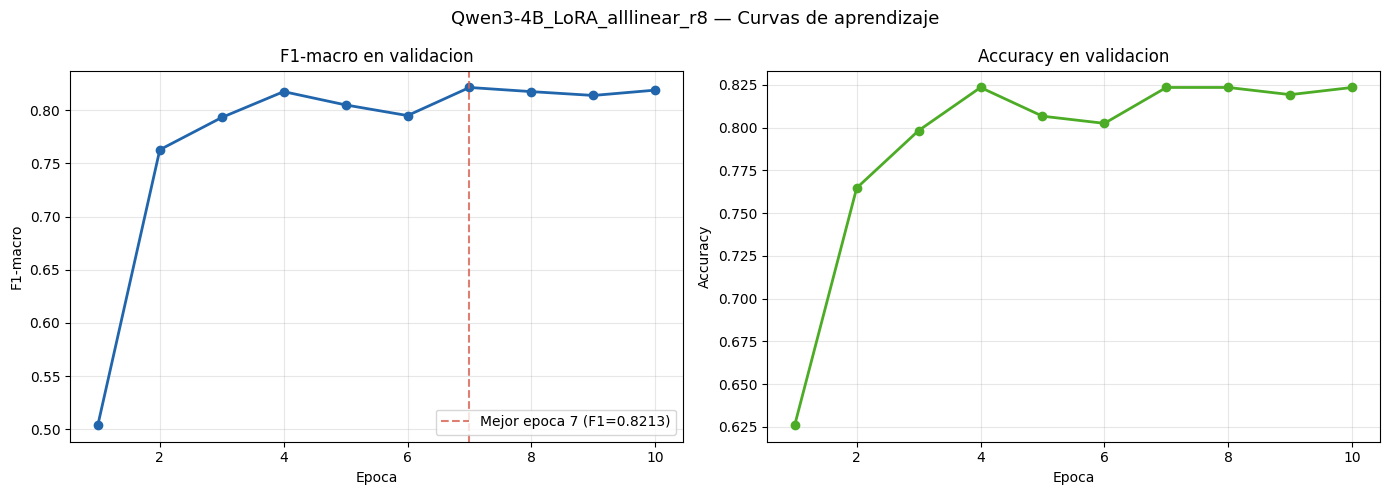

Grafica guardada: /content/drive/MyDrive/TFM/qwen3_4b_lora_alllinear_r8/learning_curves.png


In [18]:
log_history = trainer.state.log_history
val_logs = [x for x in log_history if 'eval_f1_macro' in x]

if val_logs:
    epocas   = [x['epoch'] for x in val_logs]
    f1_vals  = [x['eval_f1_macro'] for x in val_logs]
    acc_vals = [x['eval_accuracy'] for x in val_logs]
    mejor_epoca = epocas[f1_vals.index(max(f1_vals))]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epocas, f1_vals, 'o-', color='#2166ac', linewidth=2, markersize=6)
    axes[0].axvline(mejor_epoca, color='#d6604d', linestyle='--', alpha=0.8,
                    label=f'Mejor epoca {mejor_epoca:.0f} (F1={max(f1_vals):.4f})')
    axes[0].set_xlabel('Epoca')
    axes[0].set_ylabel('F1-macro')
    axes[0].set_title('F1-macro en validacion')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epocas, acc_vals, 'o-', color='#4dac26', linewidth=2, markersize=6)
    axes[1].set_xlabel('Epoca')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Accuracy en validacion')
    axes[1].grid(True, alpha=0.3)

    plt.suptitle('Qwen3-4B_LoRA_alllinear_r8 — Curvas de aprendizaje', fontsize=13)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR + '/learning_curves.png', dpi=130, bbox_inches='tight')
    plt.show()
    print(f'Grafica guardada: {OUTPUT_DIR}/learning_curves.png')
else:
    print('No hay logs de validacion disponibles')


In [19]:
log_history = trainer.state.log_history
val_logs    = [x for x in log_history if 'eval_f1_macro' in x]
train_logs  = [x for x in log_history if 'loss' in x and 'eval_loss' not in x]

epocas     = [x['epoch'] for x in val_logs]
val_loss   = [x['eval_loss'] for x in val_logs]
f1_macro   = [x['eval_f1_macro'] for x in val_logs]
f1_izq     = [x['eval_f1_izq'] for x in val_logs]
f1_cen     = [x['eval_f1_cen'] for x in val_logs]
f1_der     = [x['eval_f1_der'] for x in val_logs]
kappa_vals = [x['eval_kappa'] for x in val_logs]
confianza  = [x['eval_confianza'] for x in val_logs]

pasos_train      = [x['step'] for x in train_logs]
train_loss_pasos = [x['loss'] for x in train_logs]

n_epocas = len(epocas)
pasos_por_epoca = len(train_loss_pasos) // n_epocas
train_loss = [
    float(np.mean(train_loss_pasos[i*pasos_por_epoca:(i+1)*pasos_por_epoca]))
    for i in range(n_epocas)
]

mejor_epoca = epocas[f1_macro.index(max(f1_macro))]
mejor_f1    = max(f1_macro)

print("Train loss por época:", [f'{x:.4f}' for x in train_loss])
print("Val   loss por época:", [f'{x:.4f}' for x in val_loss])
print("Gap   (val-train)   :", [f'{v-t:.4f}' for v,t in zip(val_loss, train_loss)])

Train loss por época: ['12.2605', '5.5697', '2.4832', '0.7754', '0.1561', '0.0619', '0.0017', '0.0000', '0.0000', '0.0000']
Val   loss por época: ['0.8100', '0.5610', '0.5238', '0.8386', '1.5571', '1.6093', '1.4908', '1.5900', '1.5554', '1.5616']
Gap   (val-train)   : ['-11.4504', '-5.0087', '-1.9594', '0.0632', '1.4010', '1.5473', '1.4891', '1.5900', '1.5554', '1.5615']


In [20]:
print('\n1. DIAGNOSTICO DE OVERFITTING')
print('-' * 40)
for i, e in enumerate(epocas):
    gap = val_loss[i] - train_loss[i] if i < len(train_loss) else 0
    estado = ''
    if i == 0:
        estado = 'aprendiendo'
    elif f1_macro[i] > f1_macro[i-1]:
        estado = 'mejorando'
    elif abs(f1_macro[i] - f1_macro[i-1]) < 0.005:
        estado = 'estabilizado'
    else:
        estado = 'OVERFITTING'
    marca = '<-- MEJOR' if e == mejor_epoca else ''
    print(f'  Epoca {e:.0f}: Val Loss {val_loss[i]:.4f}  F1 {f1_macro[i]:.4f}  [{estado}] {marca}')


1. DIAGNOSTICO DE OVERFITTING
----------------------------------------
  Epoca 1: Val Loss 0.8100  F1 0.5043  [aprendiendo] 
  Epoca 2: Val Loss 0.5610  F1 0.7628  [mejorando] 
  Epoca 3: Val Loss 0.5238  F1 0.7931  [mejorando] 
  Epoca 4: Val Loss 0.8386  F1 0.8174  [mejorando] 
  Epoca 5: Val Loss 1.5571  F1 0.8049  [OVERFITTING] 
  Epoca 6: Val Loss 1.6093  F1 0.7949  [OVERFITTING] 
  Epoca 7: Val Loss 1.4908  F1 0.8213  [mejorando] <-- MEJOR
  Epoca 8: Val Loss 1.5900  F1 0.8174  [estabilizado] 
  Epoca 9: Val Loss 1.5554  F1 0.8138  [estabilizado] 
  Epoca 10: Val Loss 1.5616  F1 0.8188  [mejorando] 


In [21]:
print('    Diagnóstico overfitting basado en val_loss y F1\n')

PATIENCE  = 3
MIN_DELTA = 0.005
GAP_ALERT = 0.3

mejor_vl              = float('inf')
mejor_vl_epoca        = 1
epocas_sin_mejora     = 0

for i, e in enumerate(epocas):

    gap = val_loss[i] - train_loss[i]

    # Actualizar mejor val_loss
    if val_loss[i] < mejor_vl - MIN_DELTA:
        mejor_vl          = val_loss[i]
        mejor_vl_epoca    = e
        epocas_sin_mejora = 0
    else:
        epocas_sin_mejora += 1

    # Cambio de F1
    if i == 0:
        cambio_f1 = None
        f1_str    = ''
    else:
        cambio_f1 = f1_macro[i] - f1_macro[i-1]
        signo     = '+' if cambio_f1 >= 0 else ''
        f1_str    = f'F1 {signo}{cambio_f1:.4f}'

    # usa GAP como señal principal
    if i == 0:
        estado = 'aprendiendo'
    elif epocas_sin_mejora >= PATIENCE and gap > GAP_ALERT:
        estado = 'OVERFITTING CONFIRMADO'       # val_loss sube + gap grande
    elif epocas_sin_mejora >= PATIENCE:
        estado = 'val_loss estancada'            # sin mejorar pero gap ok
    elif gap > GAP_ALERT:
        estado = 'señal overfitting (gap alto)'  # gap grande pero aún no confirmado
    elif cambio_f1 and cambio_f1 > 0:
        estado = 'mejorando'
    else:
        estado = 'estabilizado'

    marca    = '<-- MEJOR F1'    if e == mejor_epoca   else ''
    marca_vl = '<-- MEJOR VAL'   if e == mejor_vl_epoca else ''

    print(f'  Época {e:2.0f} | '
          f'Train {train_loss[i]:.4f} | '
          f'Val {val_loss[i]:.4f} | '
          f'Gap {gap:+.4f} | '
          f'F1 {f1_macro[i]:.4f} ({f1_str:12s}) | '
          f'{estado:35s} {marca} {marca_vl}')

    Diagnóstico overfitting basado en val_loss y F1

  Época  1 | Train 12.2605 | Val 0.8100 | Gap -11.4504 | F1 0.5043 (            ) | aprendiendo                          <-- MEJOR VAL
  Época  2 | Train 5.5697 | Val 0.5610 | Gap -5.0087 | F1 0.7628 (F1 +0.2585  ) | mejorando                            <-- MEJOR VAL
  Época  3 | Train 2.4832 | Val 0.5238 | Gap -1.9594 | F1 0.7931 (F1 +0.0303  ) | mejorando                            <-- MEJOR VAL
  Época  4 | Train 0.7754 | Val 0.8386 | Gap +0.0632 | F1 0.8174 (F1 +0.0243  ) | mejorando                            
  Época  5 | Train 0.1561 | Val 1.5571 | Gap +1.4010 | F1 0.8049 (F1 -0.0125  ) | señal overfitting (gap alto)         
  Época  6 | Train 0.0619 | Val 1.6093 | Gap +1.5473 | F1 0.7949 (F1 -0.0100  ) | OVERFITTING CONFIRMADO               
  Época  7 | Train 0.0017 | Val 1.4908 | Gap +1.4891 | F1 0.8213 (F1 +0.0264  ) | OVERFITTING CONFIRMADO              <-- MEJOR F1 
  Época  8 | Train 0.0000 | Val 1.5900 | Gap +1.5900 |

In [22]:
print('\n2. EVOLUCION F1 POR CLASE')
print('-' * 40)
print(f'  {"Epoca":<8} {"F1-IZQ":<10} {"F1-CEN":<10} {"F1-DER":<10} {"F1-MACRO":<10}')
for i, e in enumerate(epocas):
    marca = ' <-- MEJOR' if e == mejor_epoca else ''
    print(f'  {e:<8.0f} {f1_izq[i]:<10.4f} {f1_cen[i]:<10.4f} {f1_der[i]:<10.4f} {f1_macro[i]:<10.4f}{marca}')



2. EVOLUCION F1 POR CLASE
----------------------------------------
  Epoca    F1-IZQ     F1-CEN     F1-DER     F1-MACRO  
  1        0.6267     0.7879     0.0984     0.5043    
  2        0.7665     0.7760     0.7460     0.7628    
  3        0.7719     0.8421     0.7652     0.7931    
  4        0.8395     0.8350     0.7778     0.8174    
  5        0.7821     0.8427     0.7899     0.8049    
  6        0.8077     0.8246     0.7523     0.7949    
  7        0.8072     0.8426     0.8142     0.8213     <-- MEJOR
  8        0.8176     0.8488     0.7857     0.8174    
  9        0.8125     0.8431     0.7857     0.8138    
  10       0.8125     0.8473     0.7965     0.8188    


In [23]:
print('\n3. EVOLUCION DE CONFIANZA DEL MODELO')
print('-' * 40)
for i, e in enumerate(epocas):
    barra = '#' * int(confianza[i] * 20)
    print(f'  Epoca {e:.0f}: {confianza[i]:.4f} |{barra}|')


3. EVOLUCION DE CONFIANZA DEL MODELO
----------------------------------------
  Epoca 1: 0.7277 |##############|
  Epoca 2: 0.7815 |###############|
  Epoca 3: 0.8417 |################|
  Epoca 4: 0.9510 |###################|
  Epoca 5: 0.9602 |###################|
  Epoca 6: 0.9769 |###################|
  Epoca 7: 0.9701 |###################|
  Epoca 8: 0.9739 |###################|
  Epoca 9: 0.9743 |###################|
  Epoca 10: 0.9734 |###################|


In [24]:
print('\n4. CONCLUSION')
print('-' * 40)
epoca_pico = epocas[f1_macro.index(max(f1_macro))]
f1_final   = f1_macro[-1]
degradacion = max(f1_macro) - f1_final

if degradacion > 0.02:
    print(f'  Overfitting detectado a partir de la epoca {epoca_pico:.0f}.')
    print(f'  El F1-macro cae {degradacion:.4f} puntos desde el pico hasta la epoca final.')
    print(f'  El checkpoint optimo es la epoca {epoca_pico:.0f} (F1-macro={mejor_f1:.4f}).')
    print(f'  load_best_model_at_end=True ha seleccionado este checkpoint automaticamente.')
else:
    print(f'  No se detecta overfitting significativo.')
    print(f'  El modelo se estabiliza en torno a F1-macro={mejor_f1:.4f}.')



4. CONCLUSION
----------------------------------------
  No se detecta overfitting significativo.
  El modelo se estabiliza en torno a F1-macro=0.8213.


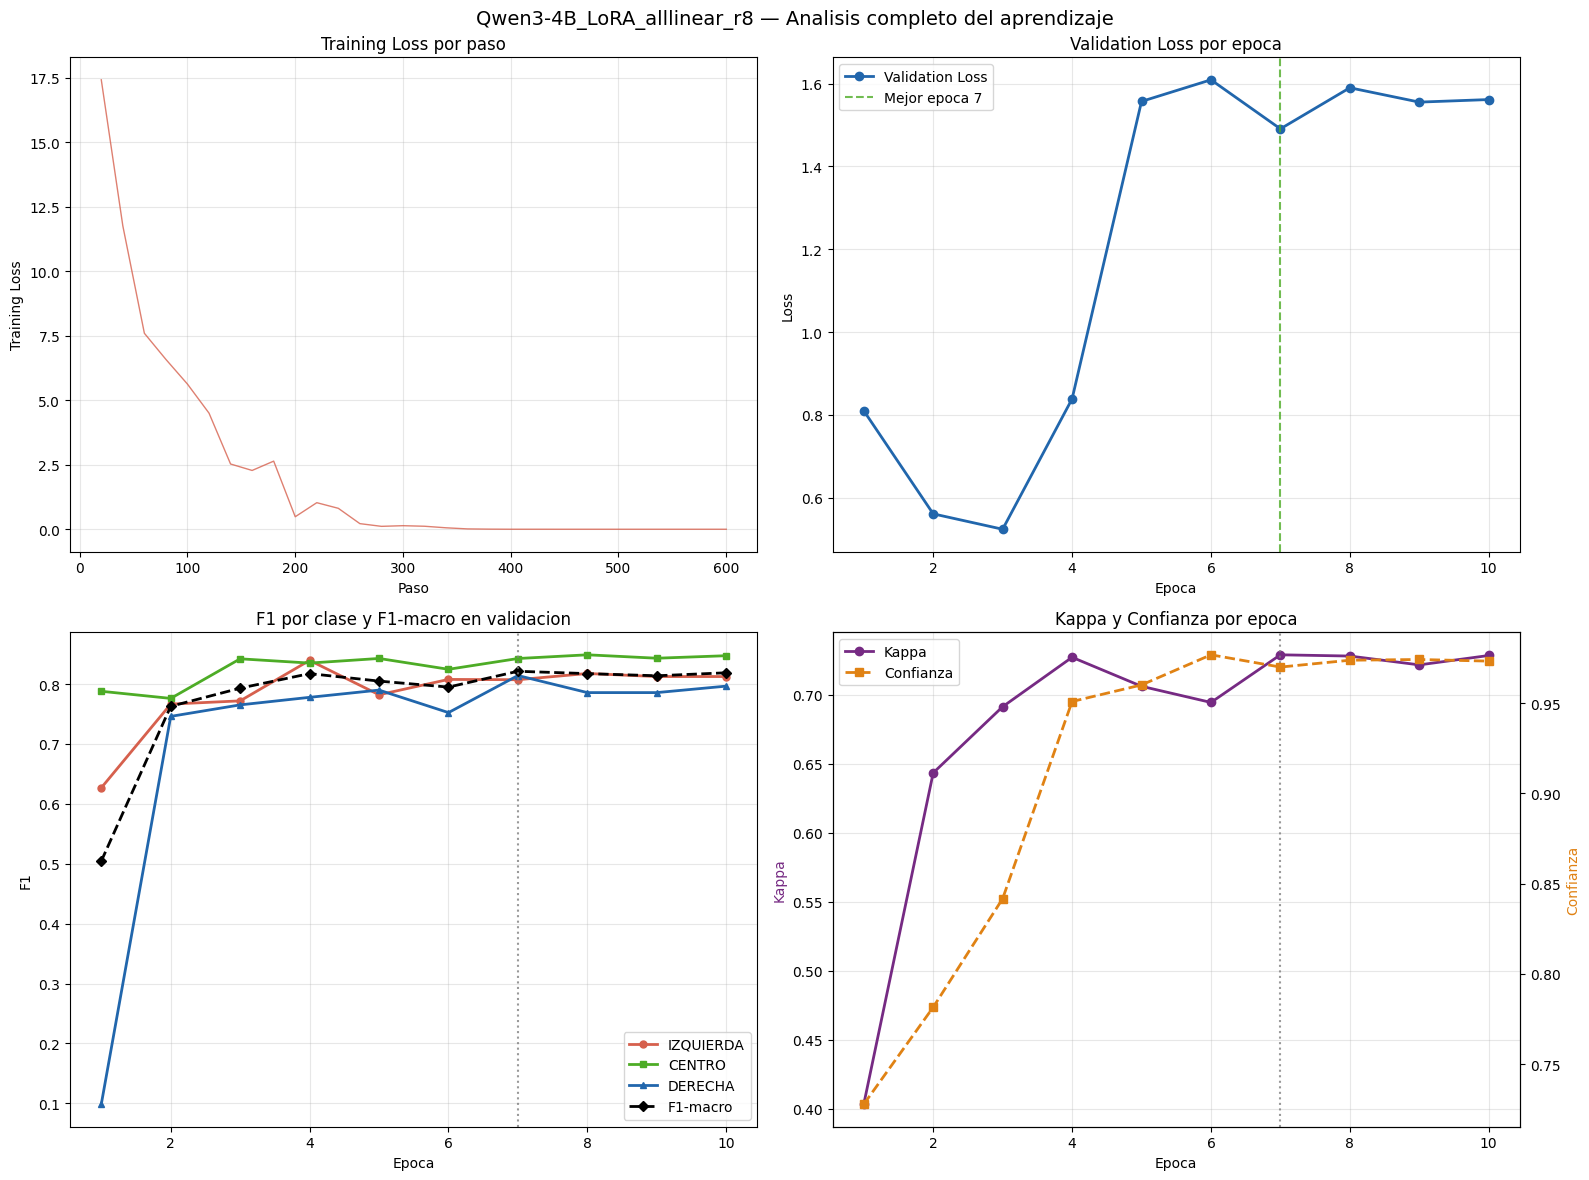


Grafica guardada: /content/drive/MyDrive/TFM/qwen3_4b_lora_alllinear_r8/analisis_aprendizaje.png


In [25]:
# Graficas
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1 — Training Loss por paso
axes[0,0].plot(pasos_train, train_loss_pasos, color='#d6604d', linewidth=1, alpha=0.8)
axes[0,0].set_xlabel('Paso')
axes[0,0].set_ylabel('Training Loss')
axes[0,0].set_title('Training Loss por paso')
axes[0,0].grid(True, alpha=0.3)

#2 — Val Loss vs Training Loss por epoca
axes[0,1].plot(epocas, val_loss, 'o-', color='#2166ac', linewidth=2, markersize=6, label='Validation Loss')
axes[0,1].axvline(mejor_epoca, color='#4dac26', linestyle='--', alpha=0.8, label=f'Mejor epoca {mejor_epoca:.0f}')
axes[0,1].set_xlabel('Epoca')
axes[0,1].set_ylabel('Loss')
axes[0,1].set_title('Validation Loss por epoca')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# 3 — F1 por clase
axes[1,0].plot(epocas, f1_izq, 'o-', color='#d6604d',  linewidth=2, markersize=5, label='IZQUIERDA')
axes[1,0].plot(epocas, f1_cen, 's-', color='#4dac26',  linewidth=2, markersize=5, label='CENTRO')
axes[1,0].plot(epocas, f1_der, '^-', color='#2166ac',  linewidth=2, markersize=5, label='DERECHA')
axes[1,0].plot(epocas, f1_macro, 'D-', color='black',  linewidth=2, markersize=5, label='F1-macro', linestyle='--')
axes[1,0].axvline(mejor_epoca, color='gray', linestyle=':', alpha=0.8)
axes[1,0].set_xlabel('Epoca')
axes[1,0].set_ylabel('F1')
axes[1,0].set_title('F1 por clase y F1-macro en validacion')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# 4 — Kappa y Confianza
ax2 = axes[1,1].twinx()
axes[1,1].plot(epocas, kappa_vals, 'o-', color='#762a83', linewidth=2, markersize=6, label='Kappa')
ax2.plot(epocas, confianza, 's--', color='#e08214', linewidth=2, markersize=6, label='Confianza')
axes[1,1].axvline(mejor_epoca, color='gray', linestyle=':', alpha=0.8)
axes[1,1].set_xlabel('Epoca')
axes[1,1].set_ylabel('Kappa', color='#762a83')
ax2.set_ylabel('Confianza', color='#e08214')
axes[1,1].set_title('Kappa y Confianza por epoca')
axes[1,1].grid(True, alpha=0.3)

lines1, labels1 = axes[1,1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1,1].legend(lines1 + lines2, labels1 + labels2)

plt.suptitle('Qwen3-4B_LoRA_alllinear_r8 — Analisis completo del aprendizaje', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/analisis_aprendizaje.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'\nGrafica guardada: {OUTPUT_DIR}/analisis_aprendizaje.png')


### Interpretación de las curvas de aprendizaje

**Panel superior izquierdo — Training Loss por paso:**
La curva desciende de forma continua. Con 16.5 M de parámetros entrenables y 1,902 ejemplos, el modelo tiene capacidad suficiente para reducir la training loss a valores muy bajos, lo que favorece el overfitting.

**Panel superior derecho — Validation Loss por época:**
La val_loss mínima se alcanza en la época 4 (F1-macro=0.8174). A partir de la época 5 sube de forma sostenida hasta 1.562 al final. La subida total es de 1.038 puntos, la mayor de toda la batería, lo que clasifica esta variante como overfitting **BASTANTE** con la severidad más alta observada.

**Panel inferior izquierdo — F1 por clase:**
Los F1 en el mejor checkpoint son: IZQUIERDA 0.807, CENTRO 0.843, DERECHA 0.814. La clase IZQUIERDA es la más difícil para esta variante. DERECHA muestra una trayectoria menos estable a lo largo de las épocas, coherente con el menor número de ejemplos de entrenamiento.

**Panel inferior derecho — Kappa y Confianza:**
El kappa de Cohen (0.7289) es el segundo más bajo de la batería. La confianza media (0.9701) es alta, contrastando con el rendimiento moderado. Esta combinación — alta confianza y F1 moderado — es característica del overfitting severo.

## 14. SHAP: Interpretabilidad con PartitionExplainer

Usamos SHAP para responder: ¿qué palabras del texto empujan la predicción hacia IZQUIERDA, CENTRO o DERECHA?


**PartitionExplainer vs KernelExplainer:**
`PartitionExplainer` usa la estructura jerárquica del texto (palabras como partición) y es mucho más eficiente que `KernelExplainer` para LLMs. Trabaja directamente sobre texto, no sobre vectores numéricos, lo que produce explicaciones en tokens
legibles.

**Salida:**
- Barplot con los 20 tokens más influyentes por clase (positivos y negativos)
- Visualización HTML de un artículo concreto con tokens coloreados por SHAP value
- CSV con todos los SHAP values guardado en Drive


In [26]:
N_SHAP_EXPLAIN  = 15   # artículos de val a explicar (más = más lento)
MAX_LEN_SHAP    = 256  # longitud máxima para SHAP (equilibrio velocidad/precisión)
TOP_K_TOKENS    = 20   # tokens más influyentes a mostrar por clase

model.eval()

def predict_text(texts):
    """Devuelve probabilidades (n, 3) para una lista de strings."""
    all_probs = []
    for i in range(0, len(texts), 8):
        batch = list(texts[i:i+8])
        enc = tokenizer(
            batch,
            truncation=True,
            max_length=MAX_LEN_SHAP,
            padding=True,
            return_tensors='pt'
        )
        enc = {k: v.to(model.device) for k, v in enc.items()}
        with torch.no_grad():
            logits = model(**enc).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()
        all_probs.append(probs)
    return np.vstack(all_probs)

# Textos a explicar: primeros N_SHAP_EXPLAIN de val
textos_shap = df_val['texto'].iloc[:N_SHAP_EXPLAIN].tolist()
labels_shap = df_val['final_label'].iloc[:N_SHAP_EXPLAIN].tolist()


masker = shap.maskers.Text(tokenizer=r"\W+")
explainer = shap.Explainer(predict_text, masker, output_names=CLASES)

print(f"Calculando SHAP values para {N_SHAP_EXPLAIN} artículos...")
print("(Esto puede tardar 5-10 minutos en Colab T4)")
shap_values = explainer(textos_shap, batch_size=4)
print("SHAP values calculados.")

# Guardar SHAP values
shap_path = OUTPUT_DIR + '/shap_values.npz'
np.savez(shap_path,
         values=shap_values.values,
         data=np.array(shap_values.data, dtype=object),
         labels=np.array(labels_shap))
print(f"SHAP values guardados: {shap_path}")


Calculando SHAP values para 15 artículos...
(Esto puede tardar 5-10 minutos en Colab T4)


  0%|          | 0/498 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  27%|██▋       | 4/15 [00:18<00:20,  1.85s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

...

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  93%|█████████▎| 14/15 [01:16<00:05,  5.23s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 16it [01:26,  6.20s/it]

SHAP values calculados.
SHAP values guardados: /content/drive/MyDrive/TFM/qwen3_4b_lora_alllinear_r8/shap_values.npz


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
colores_clase = {'IZQUIERDA': '#d6604d', 'CENTRO': '#4dac26', 'DERECHA': '#2166ac'}

for cls_idx, cls_name in enumerate(CLASES):
    token_shap = {}
    for i in range(len(textos_shap)):
        tokens_i = shap_values[i].data
        vals_i   = shap_values[i].values[:, cls_idx]
        for tok, val in zip(tokens_i, vals_i):
            tok_clean = tok.strip().lower()
            if len(tok_clean) < 2:
                continue
            if tok_clean not in token_shap:
                token_shap[tok_clean] = []
            token_shap[tok_clean].append(val)

    # Media de SHAP por token
    token_mean = {t: np.mean(v) for t, v in token_shap.items() if len(v) >= 1}
    df_tok = pd.DataFrame(list(token_mean.items()), columns=['token', 'shap'])
    df_tok = df_tok.reindex(df_tok['shap'].abs().nlargest(TOP_K_TOKENS).index)
    df_tok = df_tok.sort_values('shap')

    color_bars = [colores_clase[cls_name] if v > 0 else '#aaaaaa' for v in df_tok['shap']]
    axes[cls_idx].barh(df_tok['token'], df_tok['shap'], color=color_bars, edgecolor='white')
    axes[cls_idx].axvline(0, color='black', linewidth=0.8)
    axes[cls_idx].set_title(f'Top tokens — {cls_name}', fontsize=13, fontweight='bold')
    axes[cls_idx].set_xlabel('SHAP value medio')
    axes[cls_idx].grid(True, axis='x', alpha=0.3)

plt.suptitle('Qwen3-4B_LoRA_alllinear_r8 — Tokens más influyentes por clase (SHAP)', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/shap_top_tokens.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/shap_top_tokens.png")

### Interpretación del análisis SHAP

Los barplots muestran los 20 tokens más influyentes por clase, calculados sobre 15 artículos de validación.

Al adaptar todas las capas lineales, el modelo tiene la mayor superficie de modificación de toda la batería. Esto puede producir SHAP values distribuidos sobre un vocabulario amplio, con contribuciones más difusas que en variantes que adaptan solo las capas de atención. Un vocabulario muy disperso puede indicar que el modelo captura correlaciones superficiales en lugar de patrones ideológicos robustos.

In [ ]:
IDX_EJEMPLO = 0
CLS_VER     = 2

sv   = shap_values[IDX_EJEMPLO].values[:, CLS_VER]
toks = shap_values[IDX_EJEMPLO].data

# Normalizar a [-1, 1] para el colormap
vmax = max(abs(sv.max()), abs(sv.min())) + 1e-9
sv_norm = sv / vmax

cmap_pos = plt.cm.Reds
cmap_neg = plt.cm.Blues

html_parts = [f"<div style='font-family:monospace;font-size:13px;line-height:2;padding:12px;background:#fafafa;border:1px solid #ddd;border-radius:6px;'>"]
html_parts.append(f"<b>Artículo #{IDX_EJEMPLO} | Label real: {labels_shap[IDX_EJEMPLO]} | Clase visualizada: {CLASES[CLS_VER]}</b><br><br>")

for tok, val in zip(toks, sv_norm):
    if val > 0:
        rgba = cmap_pos(0.2 + 0.8 * val)
    else:
        rgba = cmap_neg(0.2 + 0.8 * abs(val))
    hex_color = mcolors.to_hex(rgba)
    text_color = '#000' if val < 0.6 else '#fff'
    html_parts.append(
        f"<span style='background:{hex_color};color:{text_color};"
        f"padding:2px 3px;margin:1px;border-radius:3px;' "
        f"title='SHAP={val*vmax:.4f}'>{tok}</span>"
    )

html_parts.append("</div>")
html_output = "".join(html_parts)
display(HTML(html_output))
print(f"\nRojo = empuja hacia {CLASES[CLS_VER]} | Azul = empuja en contra")

## 15. Análisis de errores cualitativos

La matriz de confusión indica cuántos errores hay; esta sección responde cuáles y por qué.

1. **Errores por tipo de confusión**: qué pares de clases se confunden
2. **Casos con mayor pérdida cross-entropy**: artículos más difíciles
3. **Errores con alta confianza (> 0.85)**: el modelo equivocado y muy seguro

En clasificación ideológica, los errores IZQUIERDA-DERECHA son los más graves semánticamente.

In [ ]:
rv = pd.read_csv(OUTPUT_DIR + '/val_predictions.csv')
rv['correcto']  = rv['true'] == rv['pred']
rv['longitud']  = df_val['texto'].str.len().values
rv['n_tokens']  = [len(tokenizer.encode(t, truncation=True, max_length=1024)) for t in df_val['texto'].tolist()]
rv['truncado']  = rv['n_tokens'] >= 1023

probs_mat = rv[['p_izq','p_cen','p_der']].values
label_ids = rv['true'].map(LABEL2ID).values
log_p     = np.log(probs_mat + 1e-9)
rv['loss_ce'] = -log_p[np.arange(len(label_ids)), label_ids]

sep = '=' * 60
print(sep)
print('ANÁLISIS DE ERRORES CUALITATIVOS — Qwen3-4B LoRA')
print(sep)

#Errores por tipo de confusión
errores = rv[~rv['correcto']].copy()
print(f'\n1. ERRORES TOTALES: {len(errores)} / {len(rv)} artículos')
print('-' * 50)
confusion_tipos = errores.groupby(['true','pred']).size().reset_index(name='n')
confusion_tipos = confusion_tipos.sort_values('n', ascending=False)
for _, row in confusion_tipos.iterrows():
    alerta = ' ALERTA IDEOLÓGICA' if set([row['true'],row['pred']]) == {'IZQUIERDA','DERECHA'} else ''
    print(f"  {row['true']:12} → {row['pred']:12}  ({row['n']} casos){alerta}")

# Casos con mayor pérdida (más difíciles para el modelo)
N_HARD = 5
print(f'\n2. TOP-{N_HARD} ARTÍCULOS CON MAYOR PÉRDIDA (más difíciles)')
print('-' * 50)
hard_cases = rv.nlargest(N_HARD, 'loss_ce')
for _, row in hard_cases.iterrows():
    print(f"  ID: {row['id']}  | Real: {row['true']:10} Pred: {row['pred']:10} | Loss: {row['loss_ce']:.3f} | Conf: {row['confianza']:.3f}")
    texto_preview = df_val[df_val['id']==row['id']]['texto'].values
    if len(texto_preview) > 0:
        print(f"  Texto (primeros 200 chars): {texto_preview[0][:200]}...")
    print()

# Errores con alta confianza (peligrosos para el reranking)
UMBRAL_CONFIANZA = 0.85
print(f'\n3. ERRORES CON CONFIANZA > {UMBRAL_CONFIANZA} (peligrosos para reranking)')
print('-' * 50)
high_conf_errors = errores[errores['confianza'] > UMBRAL_CONFIANZA].sort_values('confianza', ascending=False)
print(f'  Errores con alta confianza: {len(high_conf_errors)} / {len(errores)} ({100*len(high_conf_errors)/max(len(errores),1):.1f}%)')
if len(high_conf_errors) > 0:
    for _, row in high_conf_errors.head(5).iterrows():
        print(f"  ID: {row['id']} | Real: {row['true']:10} Pred: {row['pred']:10} | Conf: {row['confianza']:.3f}")
else:
    print('  No hay errores con confianza > {:.2f}. El modelo es conservador en sus errores.'.format(UMBRAL_CONFIANZA))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfica 1: Confianza en aciertos vs errores
conf_ok  = rv[rv['correcto']]['confianza']
conf_err = rv[~rv['correcto']]['confianza']

axes[0].hist(conf_ok,  bins=20, alpha=0.7, color='#4dac26', label=f'Aciertos (n={len(conf_ok)})',  density=True)
axes[0].hist(conf_err, bins=20, alpha=0.7, color='#d6604d', label=f'Errores (n={len(conf_err)})',   density=True)
axes[0].axvline(conf_ok.mean(),  color='#4dac26', linestyle='--', linewidth=2, label=f'Media aciertos: {conf_ok.mean():.3f}')
axes[0].axvline(conf_err.mean(), color='#d6604d', linestyle='--', linewidth=2, label=f'Media errores:  {conf_err.mean():.3f}')
axes[0].set_xlabel('Confianza')
axes[0].set_ylabel('Densidad')
axes[0].set_title('Confianza: aciertos vs errores')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Gráfica 2: Longitud del texto vs correcto/error
axes[1].scatter(rv[rv['correcto']]['longitud'],  rv[rv['correcto']]['loss_ce'],
                c='#4dac26', alpha=0.4, s=20, label='Acierto')
axes[1].scatter(rv[~rv['correcto']]['longitud'], rv[~rv['correcto']]['loss_ce'],
                c='#d6604d', alpha=0.8, s=40, marker='X', label='Error')
axes[1].set_xlabel('Longitud texto (caracteres)')
axes[1].set_ylabel('Pérdida cross-entropy')
axes[1].set_title('Longitud vs pérdida por ejemplo')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Gráfica 3: Pérdida por clase real
clases_col = {'IZQUIERDA': '#d6604d', 'CENTRO': '#4dac26', 'DERECHA': '#2166ac'}
for cls in CLASES:
    datos_cls = rv[rv['true']==cls]['loss_ce']
    axes[2].hist(datos_cls, bins=15, alpha=0.6, color=clases_col[cls],
                 label=f'{cls} (μ={datos_cls.mean():.3f})', density=True)
axes[2].set_xlabel('Pérdida cross-entropy')
axes[2].set_ylabel('Densidad')
axes[2].set_title('Distribución de pérdida por clase')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Qwen3-4B_LoRA_alllinear_r8 — Análisis de errores cualitativos', fontsize=13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/error_analysis.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/error_analysis.png")

### Interpretación del análisis de errores

**Gráfica izquierda — Confianza en aciertos vs errores:**
Esta variante tiene una confianza media alta (0.9701). Si la distribución de errores se solapa con la de aciertos en valores altos de confianza, el modelo no distingue cuándo va a fallar. Un solapamiento elevado es señal de sobreconfianza, frecuente en modelos con overfitting BASTANTE (subida de val_loss de 1.038 puntos, la mayor de toda la batería).

**Gráfica central — Longitud vs pérdida:**
Con 40 errores de validación (16.8 %, el mayor porcentaje junto a Full-7layers), comprobar si los errores se concentran en artículos largos (truncados) ayuda a descartar o confirmar que el límite de 1,024 tokens es un factor contribuyente.

**Gráfica derecha — Pérdida por clase real:**
Un F1-macro de 0.8213 con accuracy de 0.8235 indica que el modelo no discrimina bien entre las tres clases. La clase IZQUIERDA (F1=0.807) es la más difícil para esta variante, con la pérdida media más alta de las tres.

## 16. LIME: Explicaciones a nivel de palabras

LIME complementa SHAP trabajando a nivel de palabras completas (más legible). Se explica un artículo por clase seleccionando el clasificado correctamente con mayor confianza.

In [ ]:
def predict_lime(texts):
    """Devuelve probabilidades (n, 3) para lista de strings."""
    all_probs = []
    for i in range(0, len(texts), 8):
        batch = list(texts[i:i+8])
        enc = tokenizer(batch, truncation=True, max_length=256,
                        padding=True, return_tensors='pt')
        enc = {k: v.to(model.device) for k, v in enc.items()}
        with torch.no_grad():
            logits = model(**enc).logits
        all_probs.append(torch.softmax(logits, dim=-1).cpu().numpy())
    return np.vstack(all_probs)

explainer_lime = LimeTextExplainer(class_names=CLASES, random_state=42)

# Seleccionar 1 ejemplo por clase (aciertos con mayor confianza) ─
rv = pd.read_csv(OUTPUT_DIR + '/val_predictions.csv')
rv['correcto'] = rv['true'] == rv['pred']
rv['longitud'] = df_val['texto'].str.len().values

ejemplos_lime = {}
for cls in CLASES:
    candidatos = rv[(rv['true']==cls) & rv['correcto']].sort_values('confianza', ascending=False)
    if len(candidatos) > 0:
        idx_val = candidatos.index[0]
        ejemplos_lime[cls] = {
            'texto': df_val['texto'].iloc[idx_val],
            'id':    rv.loc[idx_val, 'id'],
            'conf':  rv.loc[idx_val, 'confianza'],
        }

# Generar explicaciones
lime_results = {}
print("Generando explicaciones LIME (puede tardar 2-3 min)...")
for cls, info in ejemplos_lime.items():
    texto_truncado = info['texto'][:2000]
    exp = explainer_lime.explain_instance(
        texto_truncado,
        predict_lime,
        num_features=15,
        num_samples=200,
        labels=[LABEL2ID[cls]]
    )
    lime_results[cls] = exp
    print(f"  {cls}: OK")

print("Explicaciones LIME generadas.")

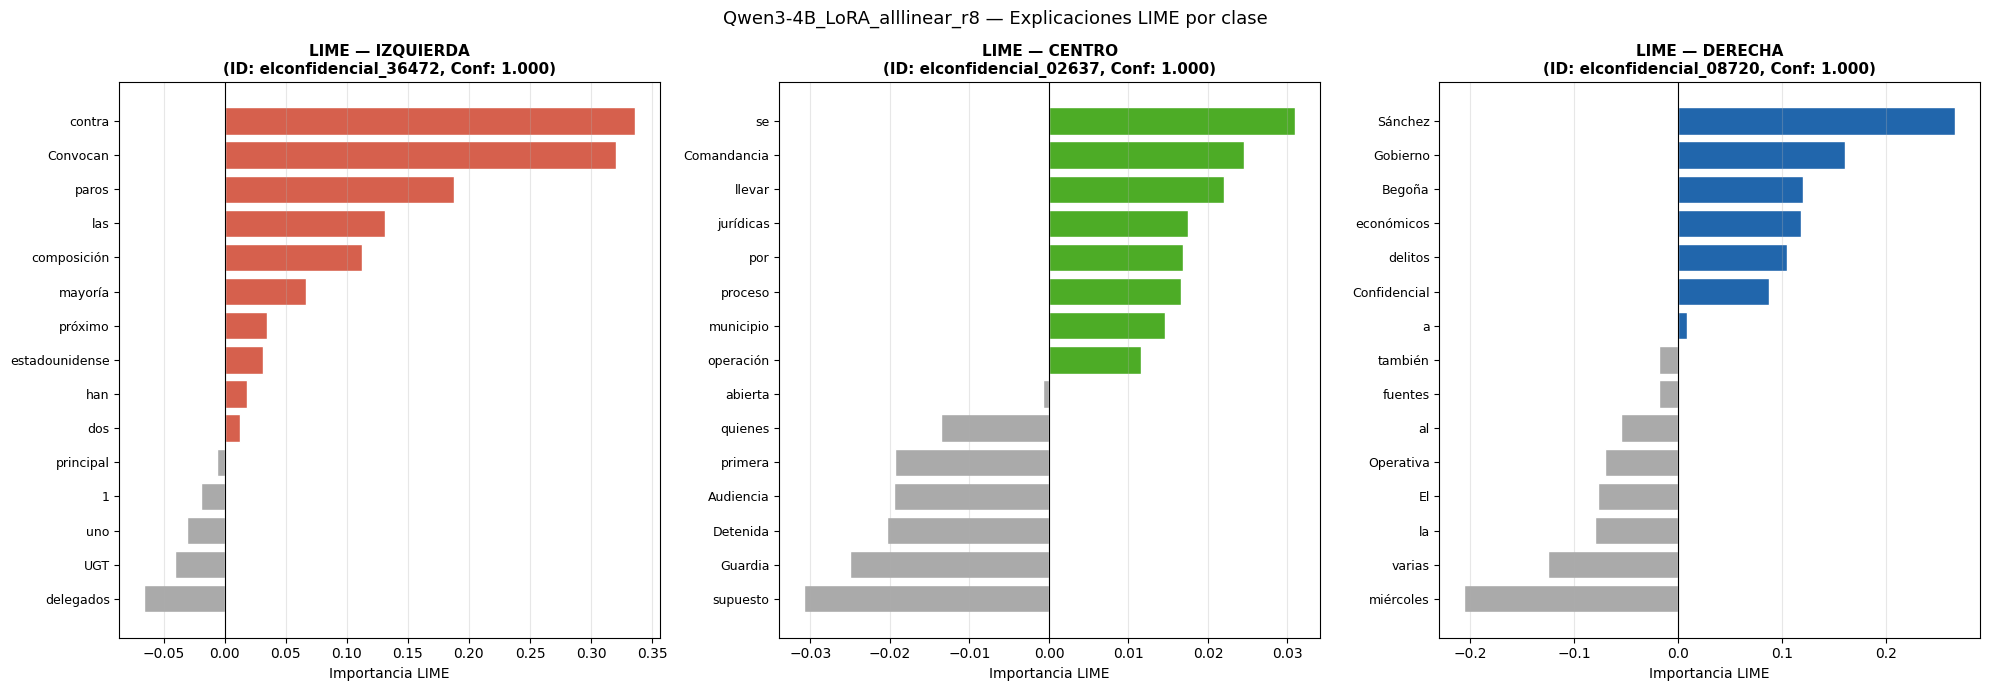

Guardado: /content/drive/MyDrive/TFM/qwen3_4b_lora_alllinear_r8/lime_explanations.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
colores_clase = {'IZQUIERDA': '#d6604d', 'CENTRO': '#4dac26', 'DERECHA': '#2166ac'}

for ax, (cls_name, exp) in zip(axes, lime_results.items()):
    cls_id  = LABEL2ID[cls_name]
    feats   = exp.as_list(label=cls_id)
    feats_sorted = sorted(feats, key=lambda x: x[1])
    palabras = [f[0] for f in feats_sorted]
    vals     = [f[1] for f in feats_sorted]
    colores  = [colores_clase[cls_name] if v > 0 else '#aaaaaa' for v in vals]

    ax.barh(palabras, vals, color=colores, edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'LIME — {cls_name}\n(ID: {ejemplos_lime[cls_name]["id"]}, Conf: {ejemplos_lime[cls_name]["conf"]:.3f})',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Importancia LIME')
    ax.grid(True, axis='x', alpha=0.3)
    ax.tick_params(axis='y', labelsize=9)

plt.suptitle('Qwen3-4B_LoRA_alllinear_r8 — Explicaciones LIME por clase', fontsize=13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/lime_explanations.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/lime_explanations.png")

### Interpretación de las explicaciones LIME

Con LoRA sobre todas las capas lineales, el modelo adapta tanto la forma en que atiende al texto (capas de atención) como cómo lo procesa internamente (capas MLP). Las explicaciones LIME pueden reflejar patrones ideológicos más complejos que en variantes que solo adaptan uno de los dos tipos de capas.

Si las palabras más influyentes para cada clase son coherentes con el léxico ideológico esperado (términos de izquierda, neutros o de derecha), confirma que el modelo ha aprendido patrones genuinos. Si aparecen tokens sorprendentes o específicos de una fuente periodística, puede indicar sobreajuste a sesgos de medios concretos.

## 17. Análisis de longitud vs. rendimiento

El 45 % de los artículos de validación (107 de 238) supera el límite de 1,024 tokens. Esta sección analiza si el truncado penaliza el rendimiento.

In [ ]:
rv = pd.read_csv(OUTPUT_DIR + '/val_predictions.csv')
rv['correcto'] = rv['true'] == rv['pred']
rv['longitud_chars']  = df_val['texto'].str.len().values
rv['n_tokens']        = [len(tokenizer.encode(t, truncation=False)) for t in df_val['texto'].tolist()]
rv['n_tokens_trunc']  = rv['n_tokens'].clip(upper=1024)
rv['pct_truncado']    = ((rv['n_tokens'] - rv['n_tokens_trunc']) / rv['n_tokens'].clip(lower=1)).clip(lower=0)
rv['truncado']        = rv['n_tokens'] > 1023

label_ids = rv['true'].map(LABEL2ID).values
pred_ids  = rv['pred'].map(LABEL2ID).values

sep = '=' * 60
print(sep)
print('ANÁLISIS DE LONGITUD VS. RENDIMIENTO — Qwen3-4B LoRA')
print(sep)

print(f'\nArticulos truncados (> 1023 tokens): {rv["truncado"].sum()} / {len(rv)} ({100*rv["truncado"].mean():.1f}%)')
print(f'Longitud media (tokens, sin truncar): {rv["n_tokens"].mean():.0f}')
print(f'Longitud mediana: {rv["n_tokens"].median():.0f}  |  p95: {rv["n_tokens"].quantile(0.95):.0f}')

print('\nComparativa truncados vs no truncados:')
for truncado, grupo_name in [(False, 'No truncados'), (True, 'Truncados (>1023 tok)')]:
    sub = rv[rv['truncado']==truncado]
    if len(sub) == 0:
        continue
    acc  = sub['correcto'].mean()
    f1m  = f1_score(sub['true'].map(LABEL2ID), sub['pred'].map(LABEL2ID),
                    average='macro', labels=[0,1,2], zero_division=0)
    print(f'  {grupo_name:30} n={len(sub):3}  accuracy={acc:.4f}  F1-macro={f1m:.4f}')

# Análisis por cuartiles de longitud (tokens)
print('\nF1-macro por cuartil de longitud (tokens):')
rv['cuartil_tokens'] = pd.qcut(rv['n_tokens'], q=4,
                                labels=['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)'])
for q in ['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)']:
    sub = rv[rv['cuartil_tokens']==q]
    f1m = f1_score(sub['true'].map(LABEL2ID), sub['pred'].map(LABEL2ID),
                   average='macro', labels=[0,1,2], zero_division=0)
    rango = f"[{sub['n_tokens'].min():.0f}-{sub['n_tokens'].max():.0f} tok]"
    print(f'  {q:15} {rango:22} n={len(sub):3}  F1-macro={f1m:.4f}  acc={sub["correcto"].mean():.4f}')

ANÁLISIS DE LONGITUD VS. RENDIMIENTO — Qwen3-4B LoRA

Articulos truncados (> 1023 tokens): 107 / 238 (45.0%)
Longitud media (tokens, sin truncar): 1093
Longitud mediana: 986  |  p95: 2056

Comparativa truncados vs no truncados:
  No truncados                   n=131  accuracy=0.8321  F1-macro=0.8192
  Truncados (>1023 tok)          n=107  accuracy=0.8131  F1-macro=0.8137

F1-macro por cuartil de longitud (tokens):
  Q1 (corto)      [116-697 tok]          n= 60  F1-macro=0.8803  acc=0.8833
  Q2              [707-986 tok]          n= 61  F1-macro=0.7948  acc=0.8197
  Q3              [990-1381 tok]         n= 57  F1-macro=0.8096  acc=0.8070
  Q4 (largo)      [1383-4191 tok]        n= 60  F1-macro=0.7758  acc=0.7833


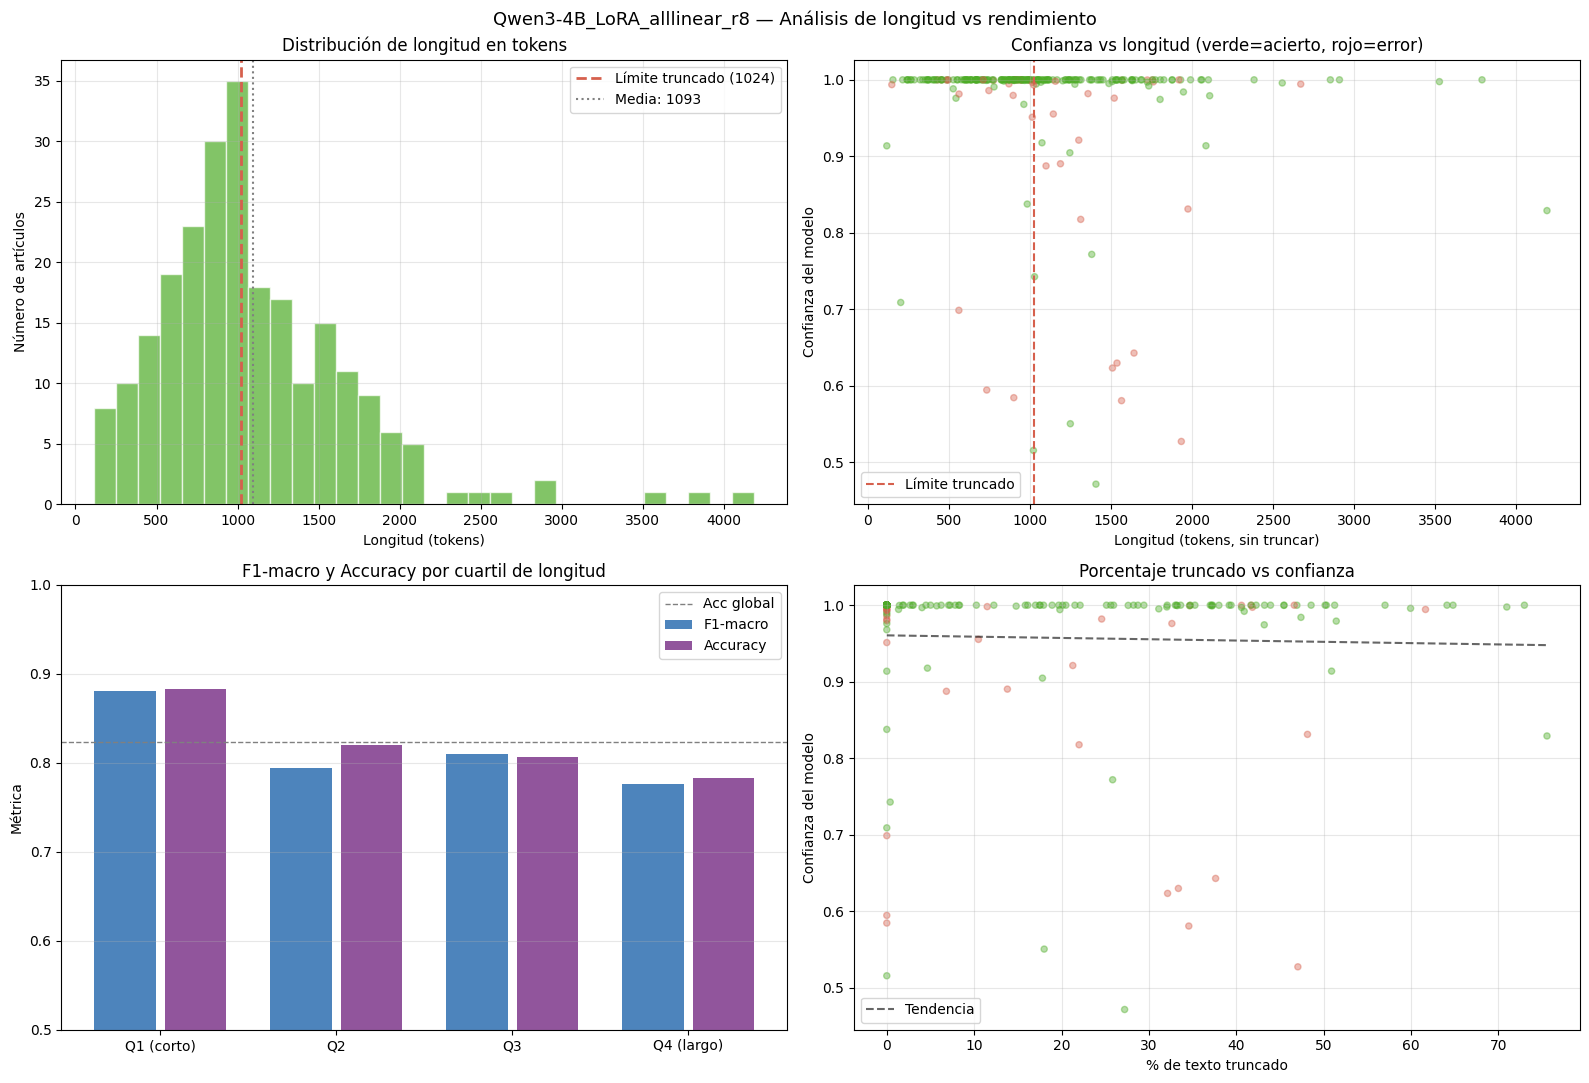

Guardado: /content/drive/MyDrive/TFM/qwen3_4b_lora_alllinear_r8/length_analysis.png
\CONCLUSIÓN:
  Los artículos largos (Q4) tienen F1 0.104 puntos peor que los cortos (Q1).
  Recomendación: explorar max_length=2048 o chunking con agregación de predicciones.


In [34]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Gráfica 1: Distribución de longitud en tokens
axes[0,0].hist(rv['n_tokens'], bins=30, color='#4dac26', alpha=0.7, edgecolor='white')
axes[0,0].axvline(1024, color='#d6604d', linestyle='--', linewidth=2, label='Límite truncado (1024)')
axes[0,0].axvline(rv['n_tokens'].mean(), color='gray', linestyle=':', linewidth=1.5, label=f"Media: {rv['n_tokens'].mean():.0f}")
axes[0,0].set_xlabel('Longitud (tokens)')
axes[0,0].set_ylabel('Número de artículos')
axes[0,0].set_title('Distribución de longitud en tokens')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Gráfica 2: Confianza vs n_tokens
colores_correcto = rv['correcto'].map({True: '#4dac26', False: '#d6604d'})
axes[0,1].scatter(rv['n_tokens'], rv['confianza'], c=colores_correcto, alpha=0.4, s=20)
axes[0,1].axvline(1024, color='#d6604d', linestyle='--', linewidth=1.5, label='Límite truncado')
axes[0,1].set_xlabel('Longitud (tokens, sin truncar)')
axes[0,1].set_ylabel('Confianza del modelo')
axes[0,1].set_title('Confianza vs longitud (verde=acierto, rojo=error)')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Gráfica 3: F1-macro por cuartil de longitud
cuartiles  = ['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)']
f1_por_q   = []
acc_por_q  = []
for q in cuartiles:
    sub = rv[rv['cuartil_tokens']==q]
    f1_por_q.append(f1_score(sub['true'].map(LABEL2ID), sub['pred'].map(LABEL2ID),
                              average='macro', labels=[0,1,2], zero_division=0))
    acc_por_q.append(sub['correcto'].mean())

x = np.arange(len(cuartiles))
axes[1,0].bar(x - 0.2, f1_por_q,  0.35, label='F1-macro',  color='#2166ac', alpha=0.8)
axes[1,0].bar(x + 0.2, acc_por_q, 0.35, label='Accuracy', color='#762a83', alpha=0.8)
axes[1,0].axhline(rv['correcto'].mean(), color='gray', linestyle='--', linewidth=1, label='Acc global')
axes[1,0].set_xticks(x); axes[1,0].set_xticklabels(cuartiles)
axes[1,0].set_ylabel('Métrica')
axes[1,0].set_title('F1-macro y Accuracy por cuartil de longitud')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3, axis='y')
axes[1,0].set_ylim(0.5, 1.0)

# Gráfica 4: % truncado vs confianza
axes[1,1].scatter(rv['pct_truncado'] * 100, rv['confianza'],
                   c=colores_correcto, alpha=0.4, s=20)
axes[1,1].set_xlabel('% de texto truncado')
axes[1,1].set_ylabel('Confianza del modelo')
axes[1,1].set_title('Porcentaje truncado vs confianza')
axes[1,1].grid(True, alpha=0.3)

# Añadir línea de tendencia
mask_valid = rv['pct_truncado'] > 0
if mask_valid.sum() > 5:
    z = np.polyfit(rv.loc[mask_valid,'pct_truncado']*100, rv.loc[mask_valid,'confianza'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(0, rv['pct_truncado'].max()*100, 50)
    axes[1,1].plot(x_line, p(x_line), 'k--', linewidth=1.5, alpha=0.6, label='Tendencia')
    axes[1,1].legend()

plt.suptitle('Qwen3-4B_LoRA_alllinear_r8 — Análisis de longitud vs rendimiento', fontsize=13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/length_analysis.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/length_analysis.png")

print('\CONCLUSIÓN:')
delta_f1 = f1_por_q[-1] - f1_por_q[0]
if delta_f1 < -0.03:
    print(f'  Los artículos largos (Q4) tienen F1 {abs(delta_f1):.3f} puntos peor que los cortos (Q1).')
    print('  Recomendación: explorar max_length=2048 o chunking con agregación de predicciones.')
elif delta_f1 > 0.03:
    print(f'  Los artículos largos (Q4) rinden MEJOR que los cortos (+{delta_f1:.3f} F1).')
    print('  El modelo aprovecha bien el contexto adicional dentro de los 1024 tokens.')
else:
    print(f'  No hay diferencia significativa de rendimiento por longitud (ΔF1={delta_f1:.3f}).')
    print('  El truncado a 1024 tokens no penaliza el rendimiento de forma relevante.')


### Interpretación del análisis de longitud

Esta variante aplica LoRA sobre todas las capas lineales, por lo que el contexto capturado en 1,024 tokens se procesa tanto por los mecanismos de atención como por las capas MLP. Si los artículos truncados rinden peor que los no truncados, indica que el modelo aprovecha más contexto cuando está disponible.

Con F1-macro de validación 0.8213 (el segundo más bajo de la batería), cualquier penalización adicional por truncado sería relevante. Si la diferencia entre Q1 (artículos cortos) y Q4 (largos) supera 0.03 puntos de F1, explorar max_length=2048 estaría justificado para esta variante.